# 04c SSP Extreme Frequency Plots

In [1]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import warnings
warnings.filterwarnings('ignore')

from cdrmip_extremes import utils, stats, plotting
from cdrmip_extremes.load_processed import load_extremes, load_land_ocean_masks
from cdrmip_extremes.configs import CDR_MODELS, PROC_DIR, FIG_DIR

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [3]:
ext_data = load_extremes(
    PROC_DIR, 'ScenarioMIP',
    outputs=['exceedances_matching_median_multimodel', 'branch_differences_matching_median_multimodel','agreement_matching'],
    # model_order=CDR_MODELS,
)

In [4]:
exceedances = ext_data['exceedances_matching_median_multimodel']
differences = ext_data['branch_differences_matching_median_multimodel']
agreement = ext_data['agreement_matching']

In [5]:
differences_union = {
    model: {
        expt: {
            ext_type: ds for ext_type, ds in ext_type_dt.items()
        } for expt, ext_type_dt in expt_dt.items()
    } for model, expt_dt in differences.items() if model in CDR_MODELS
}
exceedances_union = {
    model: {
        expt: {
            ext_type: ds for ext_type, ds in ext_type_dt.items()
        } for expt, ext_type_dt in expt_dt.items()
    } for model, expt_dt in exceedances.items() if model in CDR_MODELS
}

In [6]:
expt = 'ssp534-over'
agreement_union = {expt:{}}
for ext_type in ['cold','heat']:
    agreement_union[expt][ext_type] = extremes.calc_agreement(
        { 
            model:differences_union[model][expt][ext_type] for model in differences_union.keys()
        }
    )

In [7]:
differences_union['multi_model_median'] = {
    expt: {
        ext_type: xr.concat(
            [differences_union[model][expt][ext_type] for model in differences_union.keys()],
            dim='model',
            compat='override',
            coords='minimal'
        ).median(dim='model') for ext_type in ['heat','cold']
    }
}
exceedances_union['multi_model_median'] = {
    expt: {
        ext_type: xr.concat(
            [exceedances_union[model][expt][ext_type] for model in exceedances_union.keys()],
            dim='model',
            compat='override',
            coords='minimal'
        ).median(dim='model') for ext_type in ['heat','cold']
    }
}

Saved: /home/563/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S18.jpg


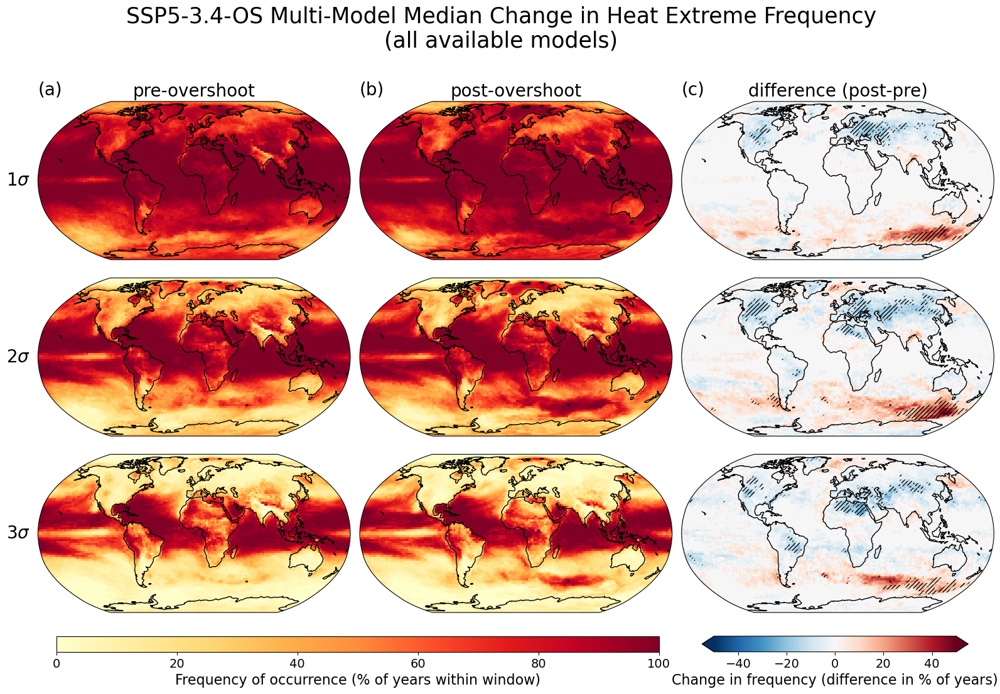

In [8]:
fig = plotting.plot_ext_freq(
    exceedances,
    differences,
    agreement, 
    model='multi_model_median',
    expt='ssp534-over',
    expt_name= 'SSP5-3.4-OS',
    ext_type='heat',
    gwl=None,
    period='equivalent',
    model_name = 'Multi-Model Median',
    suptitle = "SSP5-3.4-OS Multi-Model Median Change in Heat Extreme Frequency\n(all available models)",
    fig_dir=FIG_DIR,
    folder='supplementary',
    file_name='figure_S18.jpg'
    
)

Saved: /home/563/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S19.jpg


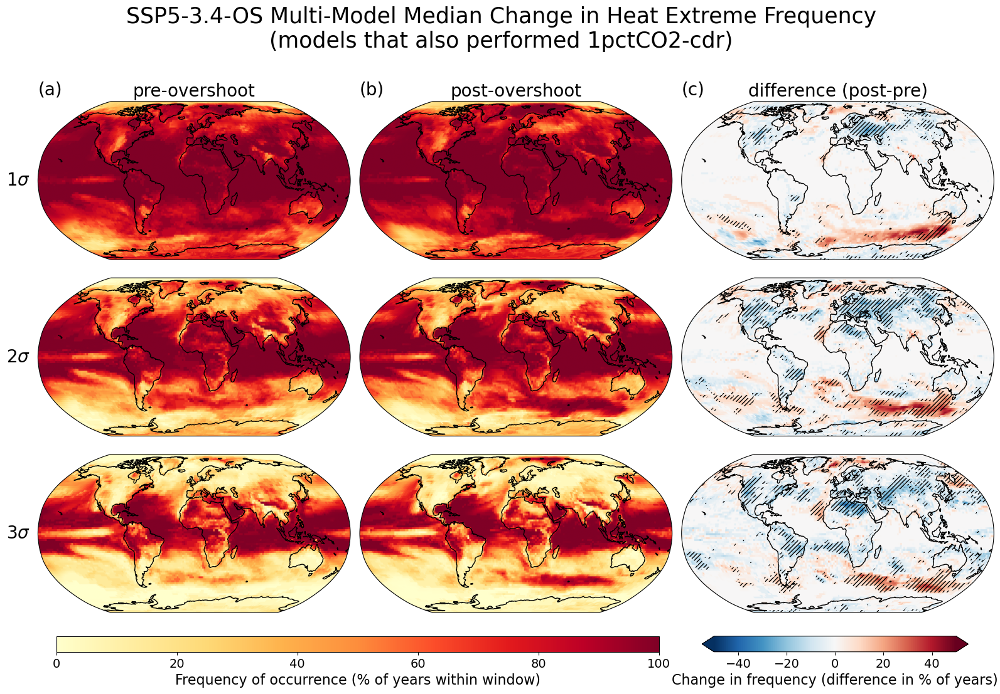

In [9]:
fig = plotting.plot_ext_freq(
    exceedances_union,
    differences_union,
    agreement_union, 
    model='multi_model_median',
    expt='ssp534-over',
    expt_name= 'SSP5-3.4-OS',
    ext_type='heat',
    gwl=None,
    period='equivalent',
    model_name = 'Multi-Model Median',
    suptitle = "SSP5-3.4-OS Multi-Model Median Change in Heat Extreme Frequency\n(models that also performed 1pctCO2-cdr)",
    fig_dir=FIG_DIR,
    folder='supplementary',
    file_name='figure_S19.jpg'
    
)

Saved: /home/563/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S20.jpg


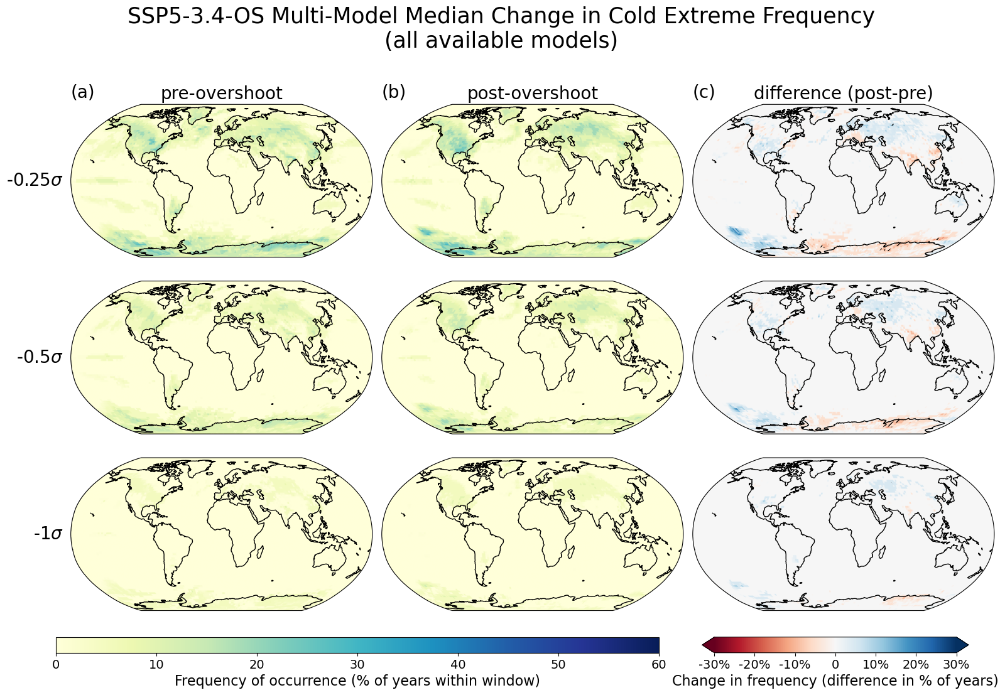

In [10]:
fig = plotting.plot_ext_freq(
    exceedances,
    differences,
    agreement, 
    model='multi_model_median',
    expt='ssp534-over',
    expt_name= 'SSP5-3.4-OS',
    ext_type='cold',
    gwl=None,
    period='equivalent',
    model_name = 'Multi-Model Median',
    suptitle = "SSP5-3.4-OS Multi-Model Median Change in Cold Extreme Frequency\n(all available models)",
    fig_dir=FIG_DIR,
    folder='supplementary',
    file_name='figure_S20.jpg' 
)

Saved: /home/563/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S21.jpg


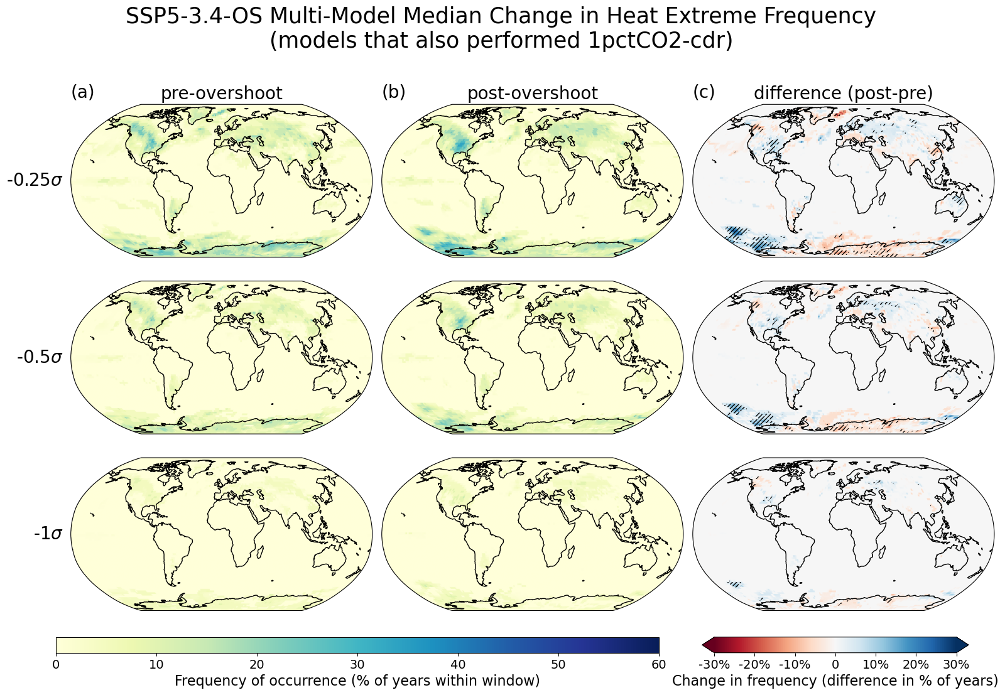

In [11]:
fig = plotting.plot_ext_freq(
    exceedances_union,
    differences_union,
    agreement_union, 
    model='multi_model_median',
    expt='ssp534-over',
    expt_name= 'SSP5-3.4-OS',
    ext_type='cold',
    gwl=None,
    period='equivalent',
    model_name = 'Multi-Model Median',
    suptitle = "SSP5-3.4-OS Multi-Model Median Change in Heat Extreme Frequency\n(models that also performed 1pctCO2-cdr)",
    fig_dir=FIG_DIR,
    folder='supplementary',
    file_name='figure_S21.jpg' 
)

## Plot differences for each model

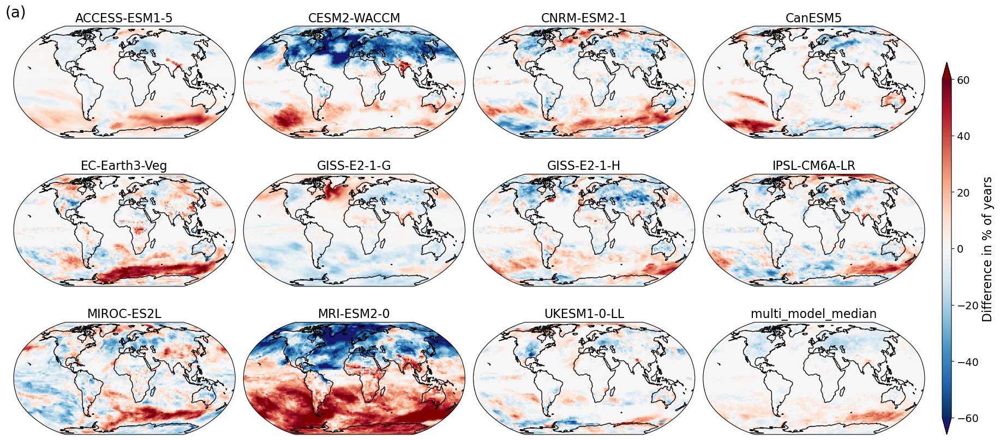

In [13]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='ssp534-over',
    ext_type='heat',
    gwl=None,
    period='matching',
    threshold='sigma1',
    levels=None,
    label='(a)',
    title='1$\sigma$',
    vmin=-60,
    vmax=60,
    exclude_models = ()
    # fig_dir=FIG_DIR,
    # folder='supplementary',
    # file_name='figure_S4a'
)

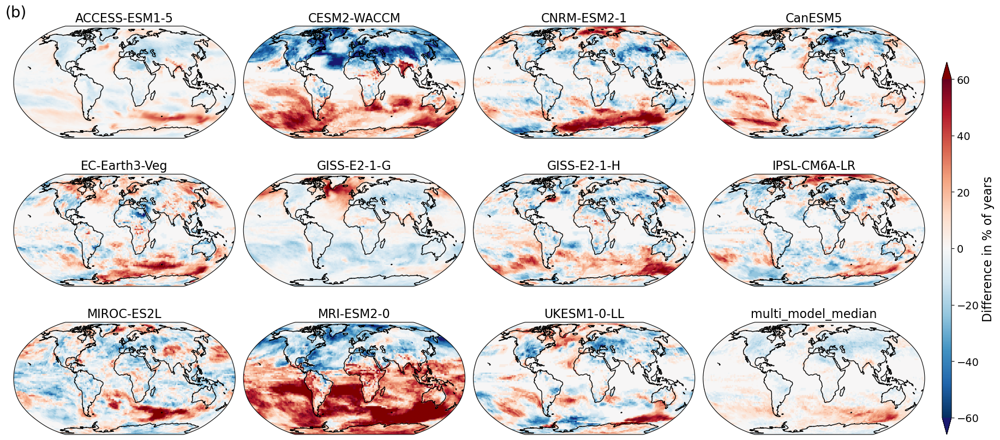

In [14]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='ssp534-over',
    ext_type='heat',
    gwl=None,
    period='matching',
    threshold='sigma2',
    levels=None,
    label='(b)',
    title='2$\sigma$',
    vmin=-60,
    vmax=60,
    exclude_models=(),
    # fig_dir=FIG_DIR,
    # folder='supplementary',
    # file_name='figure_S4a'
)

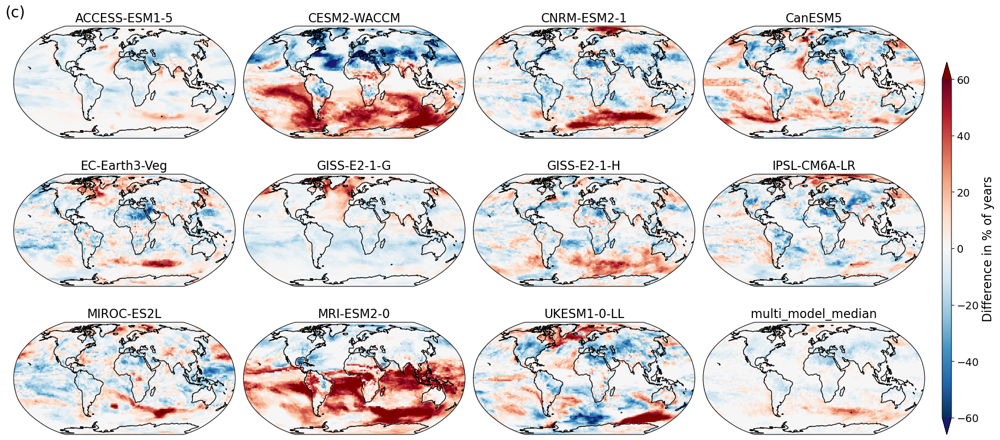

In [15]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='ssp534-over',
    ext_type='heat',
    gwl=None,
    period='matching',
    threshold='sigma3',
    levels=None,
    label='(c)',
    title='3$\sigma$',
    vmin=-60,
    vmax=60,
    exclude_models=(),
    # fig_dir=FIG_DIR,
    # folder='supplementary',
    # file_name='figure_S4a'
)

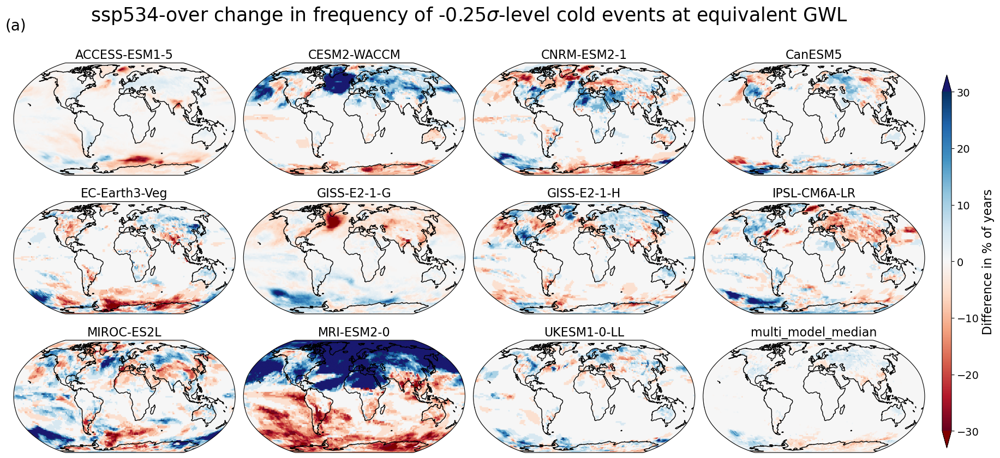

In [16]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='ssp534-over',
    ext_type='cold',
    gwl=None,
    period='equivalent',
    threshold='sigma1',
    levels=None,
    label='(a)',
    title='-0.25$\sigma$',
    vmin=-30,
    vmax=30,
    exclude_models=(),
    # fig_dir=FIG_DIR,
    # folder='supplementary',
    # file_name='figure_S4a'
)

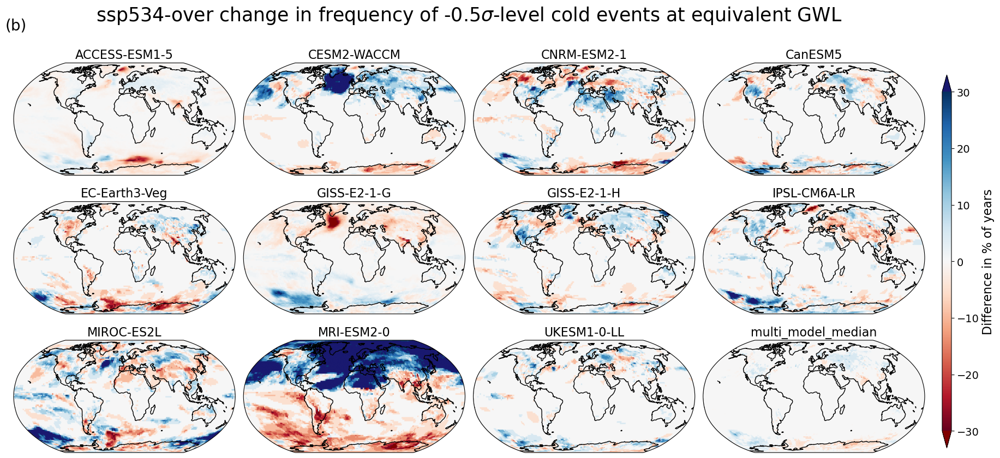

In [17]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='ssp534-over',
    ext_type='cold',
    gwl=None,
    period='equivalent',
    threshold='sigma2',
    levels=None,
    label='(b)',
    title='-0.5$\sigma$',
    vmin=-30,
    vmax=30,
    exclude_models=(),
    # fig_dir=FIG_DIR,
    # folder='supplementary',
    # file_name='figure_S4a'
)

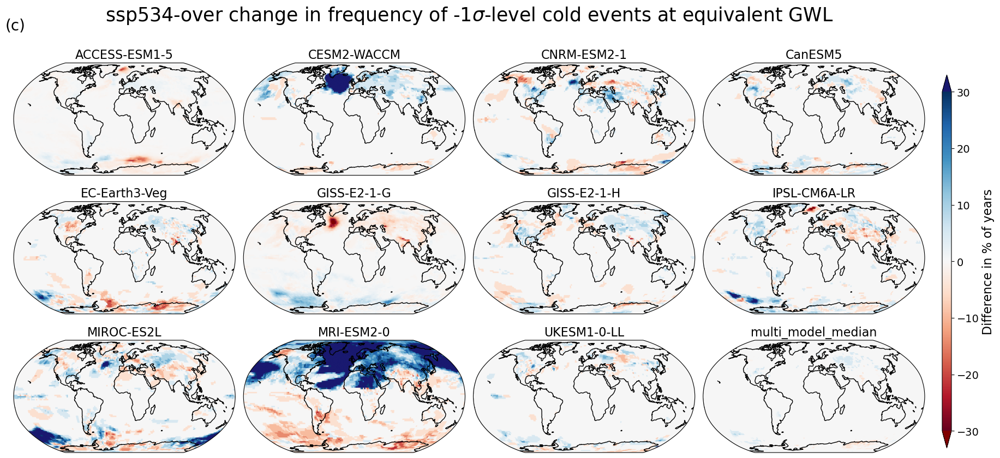

In [18]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='ssp534-over',
    ext_type='cold',
    gwl=None,
    period='equivalent',
    threshold='sigma3',
    levels=None,
    label='(c)',
    title='-1$\sigma$',
    vmin=-30,
    vmax=30,
    exclude_models=(),
    # fig_dir=FIG_DIR,
    # folder='supplementary',
    # file_name='figure_S4a'
)